### 01 · Base Gold e qualidade dos dados

Este notebook verifica a camada Gold e as bases analíticas do projeto.

Objetivos:

1. inventariar as tabelas Gold e seus grãos;
2. medir cobertura por ano, município, escola e aluno;
3. validar chaves, integridade referencial, domínios e faixas;
4. comparar o indicador municipal recalculado com o indicador Gold, quando os campos necessários estiverem disponíveis;
5. revisar as bases `base_analitica_municipio.parquet` e `base_analitica_aluno.parquet`;
6. registrar decisões para EDA e modelagem sem leakage.

> A leitura da base de alunos usa apenas colunas selecionadas ou lotes PyArrow para evitar estouro de memória.


In [3]:
from pathlib import Path
import os
import json
import gc

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

# Localiza a raiz procurando data/gold.
def localizar_raiz(inicio: Path | None = None) -> Path:
    atual = (inicio or Path.cwd()).resolve()
    for candidato in (atual, *atual.parents):
        if (candidato / "data" / "gold").exists():
            return candidato
    raise FileNotFoundError("Não foi encontrada a pasta data/gold.")

PROJECT_ROOT = localizar_raiz()
GOLD = PROJECT_ROOT / "data" / "gold"
PROCESSED = PROJECT_ROOT / "data" / "processed"
IMAGES = PROJECT_ROOT / "images"
IMAGES.mkdir(parents=True, exist_ok=True)

# Usa os módulos atuais quando disponíveis, com fallback local.
try:
    from src.visualization.plot_style import (
        aplicar_estilo,
        salvar_figura,
        formatar_percentual,
        AZUL, LARANJA, CINZA, CORES_REGIAO,
    )
    from src.visualization.business_labels import rotulo
except Exception:
    AZUL, LARANJA, CINZA = "#1f4e79", "#d9822b", "#8c8c8c"
    CORES_REGIAO = {}
    def aplicar_estilo():
        sns.set_theme(style="whitegrid", context="notebook")
    def salvar_figura(fig, nome, diretorio=IMAGES):
        diretorio.mkdir(parents=True, exist_ok=True)
        destino = diretorio / f"{nome}.png"
        fig.tight_layout()
        fig.savefig(destino, dpi=180, bbox_inches="tight", facecolor="white")
        return destino
    def formatar_percentual(ax, eixo="x", casas=0):
        import matplotlib as mpl
        fmt = mpl.ticker.FuncFormatter(lambda v, _: f"{v:.{casas}f}%")
        (ax.xaxis if eixo == "x" else ax.yaxis).set_major_formatter(fmt)
    def rotulo(nome):
        return str(nome).replace("_", " ").capitalize()

aplicar_estilo()
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

print(f"Projeto: {PROJECT_ROOT}")
print(f"Gold: {GOLD}")
print(f"Processed: {PROCESSED}")


Projeto: /home/linux/projetos/Teste_02112026
Gold: /home/linux/projetos/Teste_02112026/data/gold
Processed: /home/linux/projetos/Teste_02112026/data/processed


### 1. Inventário da camada Gold

> O inventário é obtido dos Parquets realmente existente. Os grãos abaixo correspondem ao contrato atual.


In [4]:
GRAOS = {
    "dim_estado": "uma UF",
    "dim_municipio": "um município",
    "fato_aluno": "ano × aluno",
    "contexto_municipio": "um município",
    "ideb_municipio": "ano × município × rede",
    "indicador_municipio": "ano × município × rede",
    "metas_municipio": "ano × município × rede",
    "metas_uf": "ano × UF × rede",
    "meta_brasil": "ano × rede",
    "comparacao_meta_uf": "ano × UF × rede",
    "agregado_avaliacao_municipio": "ano × município × rede",
    "agregado_avaliacao_uf": "ano × UF × rede",
    "manifesto_gold": "uma linha por tabela Gold",
}

arquivos_gold = sorted(GOLD.glob("*.parquet"))
if not arquivos_gold:
    raise FileNotFoundError(f"Nenhum Parquet encontrado em {GOLD}")

linhas = []
for caminho in arquivos_gold:
    nome = caminho.stem
    pf = pq.ParquetFile(caminho)
    linhas.append({
        "tabela": nome,
        "linhas": pf.metadata.num_rows,
        "colunas": pf.metadata.num_columns,
        "grao_esperado": GRAOS.get(nome, "não documentado"),
        "tamanho_mb": round(caminho.stat().st_size / 1e6, 2),
    })

inventario = pd.DataFrame(linhas).sort_values("tabela").reset_index(drop=True)
display(inventario)


,tabela,linhas,colunas,grao_esperado,tamanho_mb
0,agregado_avaliacao_municipio,16583,20,ano × município × rede,0.46
1,agregado_avaliacao_uf,76,18,ano × UF × rede,0.02
2,comparacao_meta_uf,79,11,ano × UF × rede,0.01
3,contexto_municipio,5571,34,um município,0.74
4,dim_estado,27,5,uma UF,0.00
5,dim_municipio,5571,7,um município,0.07
6,fato_aluno,6090791,16,ano × aluno,47.91
7,ideb_municipio,159687,15,ano × município × rede,2.97
8,indicador_municipio,16194,16,ano × município × rede,0.15
9,manifesto_gold,12,7,uma linha por tabela Gold,0.01


In [5]:
def ler_gold(nome: str, columns=None) -> pd.DataFrame:
    caminho = GOLD / f"{nome}.parquet"
    if not caminho.exists():
        raise FileNotFoundError(caminho)
    return pd.read_parquet(caminho, columns=columns)

# Tabelas pequenas e médias usadas ao longo do notebook.
dim = ler_gold("dim_municipio")
indicador = ler_gold("indicador_municipio")
metas = ler_gold("metas_municipio")
ideb = ler_gold("ideb_municipio")
contexto = ler_gold("contexto_municipio")
comparacao_uf = ler_gold("comparacao_meta_uf")

for df in (dim, indicador, metas, ideb, contexto, comparacao_uf):
    df.drop(columns="_gold_processed_at", errors="ignore", inplace=True)

display(indicador.head())


,id_municipio,nome_municipio,sigla_uf,rede,ano,indicador_pct,nivel,participacao_pct,ano_fonte,meta_municipio,id_uf,nome_uf,nome_regiao,atingiu_meta,gap_meta_pp
0,1100015,Alta Floresta D'Oeste,RO,municipal,2023,65.0,4,92.0,2025,<NA>,11,Rondônia,Norte,<NA>,<NA>
1,1100023,Ariquemes,RO,municipal,2023,62.0,4,89.0,2025,<NA>,11,Rondônia,Norte,<NA>,<NA>
2,1100031,Cabixi,RO,municipal,2023,69.0,5,95.0,2025,<NA>,11,Rondônia,Norte,<NA>,<NA>
3,1100049,Cacoal,RO,municipal,2023,63.0,5,92.0,2025,<NA>,11,Rondônia,Norte,<NA>,<NA>
4,1100056,Cerejeiras,RO,municipal,2023,59.0,5,96.0,2025,<NA>,11,Rondônia,Norte,<NA>,<NA>


### 2. Cobertura

A cobertura de alunos é calculada lendo apenas as colunas necessárias do Parquet. No projeto atual, o campo de preenchimento é `in_preenchimento_lp`.


In [6]:
# Cobertura municipal da série oficial.
agg_ind = {
    "municipios_com_resultado": ("indicador_pct", "count"),
    "indicador_medio": ("indicador_pct", "mean"),
}
if "participacao_pct" in indicador.columns:
    agg_ind["participacao_media"] = ("participacao_pct", "mean")
if "meta_municipio" in indicador.columns:
    agg_ind["municipios_com_meta"] = ("meta_municipio", "count")

cobertura = indicador.groupby("ano").agg(**agg_ind).round(1)
cobertura["pct_dos_5570_municipios"] = (
    100 * cobertura["municipios_com_resultado"] / 5570
).round(1)
display(cobertura)


,municipios_com_resultado,indicador_medio,participacao_media,municipios_com_meta,pct_dos_5570_municipios
ano,,,,,
2023,5357,60.5,93.1,0,96.2
2024,5352,63.0,93.1,5347,96.1
2025,5485,72.0,93.0,5439,98.5


In [7]:
COLUNAS_ALUNO_COBERTURA = [
    "ano", "id_aluno", "id_escola", "id_municipio", "sigla_uf",
    "presente", "in_preenchimento_lp", "alfabetizado",
]

schema_aluno = pq.ParquetFile(GOLD / "fato_aluno.parquet").schema.names
cols = [c for c in COLUNAS_ALUNO_COBERTURA if c in schema_aluno]
alunos_cov = pd.read_parquet(GOLD / "fato_aluno.parquet", columns=cols)

alunos_cov["presente_num"] = pd.to_numeric(alunos_cov["presente"], errors="coerce")
alunos_cov["preencheu_num"] = pd.to_numeric(
    alunos_cov.get("in_preenchimento_lp"), errors="coerce"
)

por_ano = alunos_cov.groupby("ano").agg(
    alunos_listados=("id_aluno", "size"),
    presentes=("presente_num", "sum"),
    escolas=("id_escola", "nunique"),
    municipios=("id_municipio", "nunique"),
    ufs=("sigla_uf", "nunique"),
)
por_ano["taxa_presenca_pct"] = (
    100 * por_ano["presentes"] / por_ano["alunos_listados"]
).round(1)

mascara_avaliados = alunos_cov["presente_num"].eq(1) & alunos_cov["preencheu_num"].eq(1)
por_ano["avaliados_com_prova"] = alunos_cov.loc[mascara_avaliados].groupby("ano").size()
por_ano["alfabetizados_pct_bruto"] = (
    100 * alunos_cov.loc[mascara_avaliados].groupby("ano")["alfabetizado"].mean()
).round(1)
display(por_ano)

del alunos_cov
gc.collect()


,alunos_listados,presentes,escolas,municipios,ufs,taxa_presenca_pct,avaliados_com_prova,alfabetizados_pct_bruto
ano,,,,,,,,
2023,1747439,1503058,36776,4873,23,86.0,1502809,58.4
2024,2120560,1852788,42497,5519,26,87.4,1851852,59.8
2025,2222792,1969921,43644,5556,27,88.6,1966605,66.3


46

A tabela acima mostra três movimentos simultâneos:

A cobertura aumentou, passando de 23 para 27 UFs e de 4.873 para 5.556 municípios.
A presença melhorou, de 86,0% para 88,6%.
A proporção bruta de alfabetizados cresceu, principalmente entre 2024 e 2025.

Contudo, parte da diferença entre os anos pode estar associada à ampliação da cobertura territorial. Por isso, o avanço de 58,4% para 66,3% não deve ser interpretado isoladamente como efeito de uma política específica.

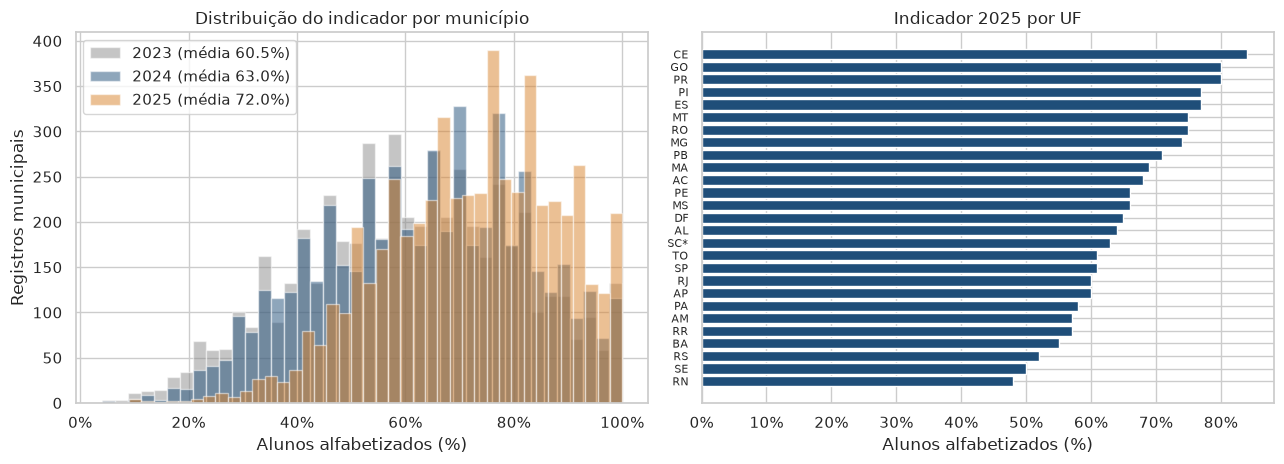

In [8]:
# Distribuição municipal e comparação por UF, adaptadas às colunas existentes.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

anos = sorted(pd.to_numeric(indicador["ano"], errors="coerce").dropna().astype(int).unique())
cores = [CINZA, AZUL, LARANJA, "#3b7a57", "#6c5b7b"]
for ano, cor in zip(anos, cores):
    serie = indicador.loc[indicador["ano"] == ano, "indicador_pct"].dropna()
    if not serie.empty:
        axes[0].hist(
            serie, bins=40, alpha=0.5, color=cor,
            label=f"{ano} (média {serie.mean():.1f}%)",
        )
axes[0].set_title("Distribuição do indicador por município")
axes[0].set_xlabel("Alunos alfabetizados (%)")
axes[0].set_ylabel("Registros municipais")
axes[0].legend()
formatar_percentual(axes[0])

ano_uf = int(pd.to_numeric(comparacao_uf["ano"], errors="coerce").max())
filtro = comparacao_uf["ano"].eq(ano_uf)
if "fonte" in comparacao_uf.columns:
    filtro &= comparacao_uf["fonte"].astype("string").str.lower().eq("indicador")
ordem = comparacao_uf.loc[filtro & comparacao_uf["sigla_uf"].ne("BR")].copy()
ordem = ordem.dropna(subset=["indicador_pct"]).sort_values("indicador_pct")
axes[1].barh(ordem["sigla_uf"], ordem["indicador_pct"], color=AZUL)
axes[1].set_title(f"Indicador {ano_uf} por UF")
axes[1].set_xlabel("Alunos alfabetizados (%)")
axes[1].tick_params(axis="y", labelsize=8)
formatar_percentual(axes[1])

salvar_figura(fig, "01_distribuicao_indicador_e_uf")
plt.show()


## 3. Checagens de qualidade

As verificações abaixo registram resultados reais. O notebook não afirma previamente que todas passarão.


In [9]:
checagens = []

def registrar(nome, ok, detalhe=""):
    checagens.append({
        "checagem": nome,
        "resultado": "ok" if bool(ok) else "FALHOU",
        "detalhe": detalhe,
    })

# Chaves do contrato atual.
registrar(
    "dim_municipio: id_municipio único",
    dim["id_municipio"].is_unique,
    f"{len(dim):,} linhas",
)

for nome, df, chave in [
    ("indicador_municipio", indicador, ["ano", "id_municipio", "rede"]),
    ("metas_municipio", metas, ["ano", "id_municipio", "rede"]),
    ("ideb_municipio", ideb, ["ano", "id_municipio", "rede"]),
]:
    chave_existente = [c for c in chave if c in df.columns]
    duplicadas = df.duplicated(chave_existente).sum()
    registrar(
        f"{nome}: chave {chave_existente} única",
        duplicadas == 0,
        f"{duplicadas} duplicatas",
    )

# Integridade referencial.
for nome, df in [
    ("indicador_municipio", indicador),
    ("metas_municipio", metas),
    ("ideb_municipio", ideb),
    ("contexto_municipio", contexto),
]:
    ids = df["id_municipio"].dropna()
    orfaos = (~ids.isin(dim["id_municipio"])).sum()
    registrar(f"{nome} → dim_municipio", orfaos == 0, f"{orfaos} órfãos")

# Faixas percentuais.
for nome, df, coluna in [
    ("indicador_municipio", indicador, "indicador_pct"),
    ("metas_municipio", metas, "meta_pct"),
    ("ideb_municipio", ideb, "aprovacao_ai_pct"),
]:
    if coluna in df.columns:
        serie = pd.to_numeric(df[coluna], errors="coerce").dropna()
        fora = (~serie.between(0, 100)).sum()
        registrar(f"{nome}.{coluna} entre 0 e 100", fora == 0, f"{fora} fora da faixa")

# Metas não decrescentes por município e rede.
chave_meta = [c for c in ["id_municipio", "rede"] if c in metas.columns]
m = metas.sort_values(chave_meta + ["ano"])
decresce = (m.groupby(chave_meta, dropna=False)["meta_pct"].diff() < -1e-9).sum()
registrar("metas não decrescentes", decresce == 0, f"{decresce} quedas")

# Chave do fato aluno sem carregar todas as colunas.
chave_aluno = pd.read_parquet(
    GOLD / "fato_aluno.parquet", columns=["ano", "id_aluno"]
)
dup_aluno = chave_aluno.duplicated(["ano", "id_aluno"]).sum()
registrar("fato_aluno: (ano, id_aluno) único", dup_aluno == 0, f"{dup_aluno} duplicatas")
del chave_aluno
gc.collect()

resultado_qualidade = pd.DataFrame(checagens)
display(resultado_qualidade)
print(resultado_qualidade["resultado"].value_counts())


,checagem,resultado,detalhe
0,dim_municipio: id_municipio único,ok,"5,571 linhas"
1,"indicador_municipio: chave ['ano', 'id_municip...",ok,0 duplicatas
2,"metas_municipio: chave ['ano', 'id_municipio',...",ok,0 duplicatas
3,"ideb_municipio: chave ['ano', 'id_municipio', ...",ok,0 duplicatas
4,indicador_municipio → dim_municipio,ok,0 órfãos
5,metas_municipio → dim_municipio,ok,0 órfãos
6,ideb_municipio → dim_municipio,ok,0 órfãos
7,contexto_municipio → dim_municipio,ok,0 órfãos
8,indicador_municipio.indicador_pct entre 0 e 100,ok,0 fora da faixa
9,metas_municipio.meta_pct entre 0 e 100,ok,0 fora da faixa


resultado
ok    13
Name: count, dtype: int64


### 3.1 Domínio do alvo e regra de alfabetização

A verificação considera somente alunos presentes e com `in_preenchimento_lp = 1`. A regra de corte só é avaliada se `proficiencia` estiver disponível.


In [10]:
cols_regra = [
    c for c in [
        "ano", "presente", "in_preenchimento_lp", "proficiencia", "alfabetizado"
    ] if c in schema_aluno
]
regra_df = pd.read_parquet(GOLD / "fato_aluno.parquet", columns=cols_regra)
mask = (
    pd.to_numeric(regra_df["presente"], errors="coerce").eq(1)
    & pd.to_numeric(regra_df["in_preenchimento_lp"], errors="coerce").eq(1)
)
avaliados = regra_df.loc[mask].copy()

registrar(
    "alfabetizado no domínio {0, 1}",
    avaliados["alfabetizado"].dropna().isin([0, 1]).all(),
    str(avaliados["alfabetizado"].value_counts(dropna=False).to_dict()),
)
if "proficiencia" in avaliados.columns:
    prof = pd.to_numeric(avaliados["proficiencia"], errors="coerce")
    registrar(
        "proficiência dos avaliados sem nulos",
        prof.notna().all(),
        f"faixa {prof.min():.1f} a {prof.max():.1f}",
    )
    comparaveis = prof.notna() & avaliados["alfabetizado"].notna()
    aderencia = (
        prof.loc[comparaveis].ge(743).astype(int).to_numpy()
        == avaliados.loc[comparaveis, "alfabetizado"].astype(int).to_numpy()
    ).mean()
    registrar(
        "alfabetizado == (proficiencia >= 743)",
        np.isclose(aderencia, 1.0),
        f"{100 * aderencia:.2f}% dos avaliados comparáveis",
    )

del regra_df, avaliados
gc.collect()
display(pd.DataFrame(checagens).tail(3))


,checagem,resultado,detalhe
13,"alfabetizado no domínio {0, 1}",ok,"{np.int64(1): 3287584, np.int64(0): 2033682}"
14,proficiência dos avaliados sem nulos,ok,faixa 572.4 a 904.4
15,alfabetizado == (proficiencia >= 743),ok,100.00% dos avaliados comparáveis


##### 3.2 Consistência do cálculo ponderado com o indicador Gold

Esta etapa percorre `fato_aluno.parquet` em lotes. O cálculo usa peso amostral quando `vl_peso_aluno_lp` existe. A comparação é feita por `ano`, `id_municipio` e rede mapeada a partir de `rede_codigo`.

Se a codificação de rede do arquivo for diferente, revise `MAPA_REDE`.


In [11]:
MAPA_REDE = {
    1: "federal",
    2: "estadual",
    3: "municipal",
    4: "privada",
}

necessarias = [
    "ano", "id_municipio", "rede_codigo", "presente",
    "in_preenchimento_lp", "alfabetizado", "vl_peso_aluno_lp",
]
necessarias = [c for c in necessarias if c in schema_aluno]

somas = {}
pf = pq.ParquetFile(GOLD / "fato_aluno.parquet")
for batch in pf.iter_batches(columns=necessarias, batch_size=100_000, use_threads=False):
    lote = batch.to_pandas()
    mask = (
        pd.to_numeric(lote["presente"], errors="coerce").eq(1)
        & pd.to_numeric(lote["in_preenchimento_lp"], errors="coerce").eq(1)
        & lote["id_municipio"].notna()
        & lote["alfabetizado"].notna()
    )
    lote = lote.loc[mask].copy()
    lote["rede"] = pd.to_numeric(lote["rede_codigo"], errors="coerce").map(MAPA_REDE)
    lote["peso"] = pd.to_numeric(
        lote.get("vl_peso_aluno_lp", 1.0), errors="coerce"
    ).fillna(1.0)
    lote["w_alf"] = lote["peso"] * pd.to_numeric(lote["alfabetizado"], errors="coerce")
    g = lote.groupby(["ano", "id_municipio", "rede"], observed=True).agg(
        soma_peso=("peso", "sum"),
        soma_peso_alf=("w_alf", "sum"),
        qtd_avaliados=("alfabetizado", "size"),
    )
    for idx, linha in g.iterrows():
        atual = somas.setdefault(idx, [0.0, 0.0, 0])
        atual[0] += float(linha["soma_peso"])
        atual[1] += float(linha["soma_peso_alf"])
        atual[2] += int(linha["qtd_avaliados"])
    del lote, g

calculado = pd.DataFrame(
    [
        {
            "ano": idx[0], "id_municipio": idx[1], "rede": idx[2],
            "soma_peso": valores[0], "soma_peso_alf": valores[1],
            "qtd_avaliados_calculado": valores[2],
        }
        for idx, valores in somas.items()
    ]
)
calculado["indicador_calculado"] = (
    100 * calculado["soma_peso_alf"] / calculado["soma_peso"]
)

oficial = indicador[[c for c in ["ano", "id_municipio", "rede", "indicador_pct"] if c in indicador.columns]].copy()
oficial["rede"] = oficial["rede"].astype("string").str.lower().str.strip()
comp = oficial.merge(calculado, on=["ano", "id_municipio", "rede"], how="inner")
comp["erro_abs_pp"] = (comp["indicador_pct"] - comp["indicador_calculado"]).abs()
mae = comp["erro_abs_pp"].mean()
registrar(
    "cálculo ponderado × indicador Gold",
    pd.notna(mae) and mae < 0.1,
    f"MAE = {mae:.3f} p.p. em {len(comp):,} registros comparáveis",
)

display(comp["erro_abs_pp"].describe().to_frame("erro absoluto (p.p.)"))
display(pd.DataFrame(checagens).tail(1))

del calculado, oficial, comp, somas
gc.collect()


,erro absoluto (p.p.)
count,15570.0
mean,0.316923
std,1.483161
min,0.0
25%,0.11689
50%,0.249532
75%,0.379853
max,75.0


,checagem,resultado,detalhe
16,cálculo ponderado × indicador Gold,FALHOU,"MAE = 0.317 p.p. em 15,570 registros comparáveis"


0

##### 4. Nulos e lacunas na Gold

> O relatório considera todas as tabelas pequenas e médias. `fato_aluno` é resumida separadamente para não duplicar a base inteira em memória.


In [12]:
tabelas_analise = {
    "dim_municipio": dim,
    "indicador_municipio": indicador,
    "metas_municipio": metas,
    "ideb_municipio": ideb,
    "contexto_municipio": contexto,
    "comparacao_meta_uf": comparacao_uf,
}

nulos = pd.concat(
    {
        nome: df.isna().mean().round(4)
        for nome, df in tabelas_analise.items()
    },
    names=["tabela", "coluna"],
).rename("fracao_nula")
nulos = nulos[nulos > 0].reset_index()
display(nulos.sort_values("fracao_nula", ascending=False).head(25))


,tabela,coluna,fracao_nula
32,contexto_municipio,pc_nivel_8,0.4448
40,comparacao_meta_uf,atingiu_meta,0.3671
41,comparacao_meta_uf,gap_meta_pp,0.3671
39,comparacao_meta_uf,meta_uf,0.3671
0,indicador_municipio,meta_municipio,0.3340
1,indicador_municipio,atingiu_meta,0.3340
2,indicador_municipio,gap_meta_pp,0.3340
11,ideb_municipio,ideb_meta,0.3052
4,ideb_municipio,aprovacao_1ano_pct,0.2244
8,ideb_municipio,ideb_nota_portugues,0.1527


In [13]:
# Nulos de colunas-chave do fato aluno, em lotes.
colunas_nulos_aluno = [
    c for c in [
        "ano", "id_aluno", "id_escola", "id_municipio", "sigla_uf", "rede_codigo",
        "presente", "in_preenchimento_lp", "vl_peso_aluno_lp", "proficiencia", "alfabetizado",
    ] if c in schema_aluno
]
contagem_nulos = pd.Series(0, index=colunas_nulos_aluno, dtype="int64")
total = 0
for batch in pq.ParquetFile(GOLD / "fato_aluno.parquet").iter_batches(
    columns=colunas_nulos_aluno, batch_size=100_000, use_threads=False
):
    lote = batch.to_pandas()
    total += len(lote)
    contagem_nulos = contagem_nulos.add(lote.isna().sum(), fill_value=0)

nulos_aluno = pd.DataFrame({
    "nulos": contagem_nulos.astype("int64"),
    "fracao_nula": (contagem_nulos / total).round(4),
}).sort_values("fracao_nula", ascending=False)
display(nulos_aluno)


,nulos,fracao_nula
proficiencia,769525,0.1263
vl_peso_aluno_lp,769525,0.1263
id_escola,628,0.0001
id_municipio,628,0.0001
rede_codigo,628,0.0001
id_aluno,0,0.0000
ano,0,0.0000
presente,0,0.0000
sigla_uf,0,0.0000
in_preenchimento_lp,0,0.0000


##### 5. Bases analíticas e alinhamento temporal

No projeto atual, os arquivos são:

- `base_analitica_municipio.parquet`, chave `ano_alvo × id_municipio × rede`;
- `base_analitica_aluno.parquet`, chave `ano × id_aluno`.

A base municipal contém histórico do indicador e do IDEB anterior ao ano-alvo, além de contexto estático. A base do aluno remove proficiência contemporânea das features, evitando usar diretamente o resultado da prova para prever `alfabetizado`.


In [14]:
ARQ_MUN = PROCESSED / "base_analitica_municipio.parquet"
ARQ_ALU = PROCESSED / "base_analitica_aluno.parquet"

if not ARQ_MUN.exists() or not ARQ_ALU.exists():
    raise FileNotFoundError("Execute primeiro o notebook de bases analíticas.")

abt_mun = pd.read_parquet(ARQ_MUN)
pf_alu = pq.ParquetFile(ARQ_ALU)

resumo_abt = pd.DataFrame([
    {
        "base": ARQ_MUN.name,
        "linhas": len(abt_mun),
        "colunas": abt_mun.shape[1],
        "grao": "ano_alvo × id_municipio × rede",
        "tamanho_mb": round(ARQ_MUN.stat().st_size / 1e6, 2),
    },
    {
        "base": ARQ_ALU.name,
        "linhas": pf_alu.metadata.num_rows,
        "colunas": pf_alu.metadata.num_columns,
        "grao": "ano × id_aluno",
        "tamanho_mb": round(ARQ_ALU.stat().st_size / 1e6, 2),
    },
])
display(resumo_abt)


,base,linhas,colunas,grao,tamanho_mb
0,base_analitica_municipio.parquet,43788,59,ano_alvo × id_municipio × rede,2.60
1,base_analitica_aluno.parquet,5320756,61,ano × id_aluno,18.89


In [15]:
# Referências temporais disponíveis na ABT municipal.
colunas_ref = [c for c in ["ref_ideb", "ano_censo", "ano_pib", "ano_inse"] if c in abt_mun.columns]
if colunas_ref:
    referencias = abt_mun.groupby("ano_alvo")[colunas_ref].agg(
        lambda s: ", ".join(str(int(v)) for v in sorted(pd.to_numeric(s, errors="coerce").dropna().unique()))
    )
    display(referencias)
else:
    print("A ABT atual não contém colunas ref_* além das features históricas disponíveis.")

# Regra temporal explícita para IDEB.
if "ref_ideb" in abt_mun.columns:
    viola = abt_mun["ref_ideb"].notna() & (abt_mun["ref_ideb"] >= abt_mun["ano_alvo"])
    registrar(
        "ref_ideb anterior ao ano-alvo",
        viola.sum() == 0,
        f"{viola.sum()} violações",
    )
    display(pd.DataFrame(checagens).tail(1))


,ref_ideb,ano_pib
ano_alvo,,
2023,2021,2021
2024,2023,2021
2025,2023,2021
2026,2025,2021
2027,2025,2021
2028,2025,2021
2029,2025,2021
2030,2025,2021


,checagem,resultado,detalhe
17,ref_ideb anterior ao ano-alvo,ok,0 violações


ano_alvo                                                  2023   2024  2025  2026   2027   2028   2029   2030
bloco                  variavel                                                                              
IDEB e rendimento      Ideb aprovacao 1ano pct ultimo      4.9    3.6   3.8   3.3    3.1    3.1    3.1    3.1
                       Ideb aprovacao 2ano pct ultimo      5.0    3.6   3.7   3.3    3.1    3.1    3.1    3.1
                       Ideb aprovacao ai pct ultimo        4.9    3.6   3.7   3.3    3.1    3.1    3.1    3.1
                       Ideb ideb nota matematica ultimo   13.1    4.9   5.1   3.7    3.5    3.5    3.5    3.5
                       Ideb ideb nota media ultimo        13.1    4.9   5.1   3.7    3.5    3.5    3.5    3.5
                       Ideb ideb nota portugues ultimo    13.1    4.9   5.1   3.7    3.5    3.5    3.5    3.5
                       Ideb ideb observado anterior        6.2   13.6  13.9   5.1    4.9    4.9    4.9    4.9
                       Ideb ideb observado ultimo         13.1    4.9   5.1   3.7    3.5    3.5    3.5    3.5
                       Ideb ideb observado variacao       15.1   14.8  15.1   5.9    5.7    5.7    5.7    5.7
                       Ideb ideb rendimento ultimo         4.9    3.6   3.7   3.3    3.1    3.1    3.1    3.1
histórico do indicador Gap meta t1                       100.0  100.0   3.2   1.5  100.0  100.0  100.0  100.0
                       Indicador t1                      100.0    2.2   3.1   0.7  100.0  100.0  100.0  100.0
                       Indicador t2                      100.0  100.0   3.0   3.1    0.7  100.0  100.0  100.0
                       Meta t                            100.0    0.1   0.8   0.8    0.0    0.0    0.0    0.0
                       Meta t1                           100.0  100.0   0.9   0.8    0.0    0.0    0.0    0.0
                       Nivel t1                          100.0    2.2   3.1   0.7  100.0  100.0  100.0  100.0
                       Participacao t1                   100.0    2.2   3.1   0.7  100.0  100.0  100.0  100.0
                       Salto necessario                  100.0    2.2   3.1   1.5  100.0  100.0  100.0  100.0
                       Variacao t1                       100.0  100.0   5.3   3.6  100.0  100.0  100.0  100.0
socioeconômico         Pc nivel 2                          6.0    6.0   6.0   6.0    6.0    6.0    6.0    6.0
                       Pc nivel 3                          2.3    2.4   2.4   2.4    2.4    2.4    2.4    2.4
                       Pc nivel 6                          3.0    3.1   3.2   3.2    3.1    3.1    3.1    3.1
                       Pc nivel 7                          8.1    8.1   8.2   8.2    8.1    8.1    8.1    8.1
                       Pc nivel 8                         44.2   44.3  44.5  44.5   44.3   44.3   44.3   44.3

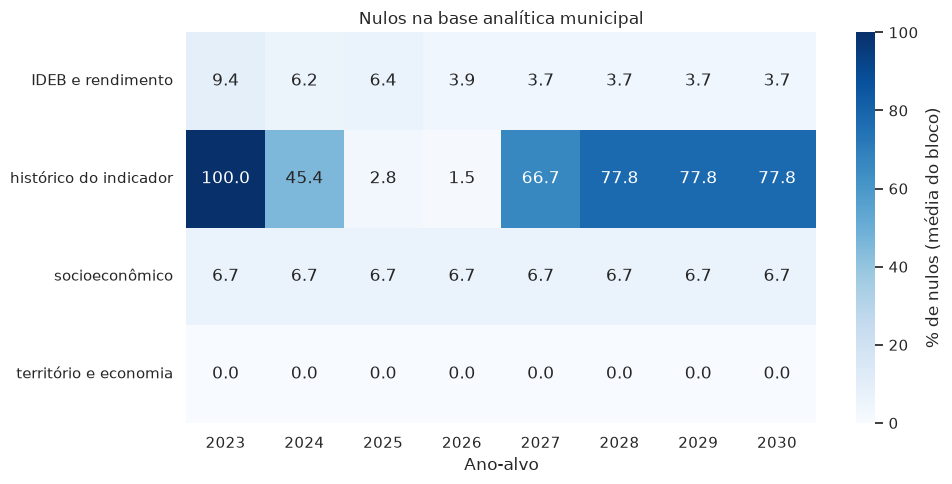

In [16]:
# Nulos por bloco, apenas com colunas existentes.
blocos = {
    "histórico do indicador": [
        "indicador_t1", "nivel_t1", "participacao_t1", "indicador_t2",
        "variacao_t1", "meta_t1", "gap_meta_t1", "meta_t", "salto_necessario",
    ],
    "IDEB e rendimento": [
        "ideb_ideb_observado_ultimo", "ideb_ideb_observado_anterior",
        "ideb_ideb_observado_variacao", "ideb_ideb_nota_portugues_ultimo",
        "ideb_ideb_nota_matematica_ultimo", "ideb_ideb_nota_media_ultimo",
        "ideb_ideb_rendimento_ultimo", "ideb_aprovacao_ai_pct_ultimo",
        "ideb_aprovacao_1ano_pct_ultimo", "ideb_aprovacao_2ano_pct_ultimo",
    ],
    "território e economia": [
        "populacao", "area_km2", "densidade_hab_km2", "pib_per_capita_reais",
        "participacao_vab_agro_pct", "participacao_vab_industria_pct",
        "participacao_vab_adm_publica_pct", "participacao_vab_servicos_pct",
    ],
    "socioeconômico": [
        "media_inse", "qtd_alunos_inse", *[f"pc_nivel_{i}" for i in range(1, 9)],
    ],
}

linhas = []
for bloco, lista in blocos.items():
    for coluna in [c for c in lista if c in abt_mun.columns]:
        for ano, grupo in abt_mun.groupby("ano_alvo"):
            linhas.append({
                "bloco": bloco,
                "variavel": rotulo(coluna),
                "ano_alvo": int(ano),
                "nulos_pct": 100 * grupo[coluna].isna().mean(),
            })

nulos_abt = pd.DataFrame(linhas)
if not nulos_abt.empty:
    tabela_nulos = nulos_abt.pivot(
        index=["bloco", "variavel"], columns="ano_alvo", values="nulos_pct"
    ).round(1)
    display(tabela_nulos[(tabela_nulos > 1).any(axis=1)])

    heat = nulos_abt.groupby(["bloco", "ano_alvo"])["nulos_pct"].mean().unstack()
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.heatmap(
        heat, annot=True, fmt=".1f", cmap="Blues",
        cbar_kws={"label": "% de nulos (média do bloco)"}, ax=ax,
    )
    ax.set_title("Nulos na base analítica municipal")
    ax.set_xlabel("Ano-alvo")
    ax.set_ylabel("")
    salvar_figura(fig, "01_nulos_base_analitica_municipio")
    plt.show()


In [17]:
# Resumo da base de aluno em lotes, sem carregá-la inteira.
cols_abt_alu = [
    c for c in ["ano", "id_aluno", "id_municipio", "id_escola", "alfabetizado", "indicador_t1"]
    if c in pf_alu.schema.names
]
acumulado = {}
for batch in pf_alu.iter_batches(columns=cols_abt_alu, batch_size=100_000, use_threads=False):
    lote = batch.to_pandas()
    for ano, g in lote.groupby("ano", observed=True):
        d = acumulado.setdefault(int(ano), {
            "alunos": 0, "alfabetizados": 0.0, "target_validos": 0,
            "municipios": set(), "escolas": set(), "sem_contexto": 0,
        })
        d["alunos"] += len(g)
        target = pd.to_numeric(g["alfabetizado"], errors="coerce")
        d["alfabetizados"] += target.sum(skipna=True)
        d["target_validos"] += target.notna().sum()
        d["municipios"].update(g["id_municipio"].dropna().astype(str))
        d["escolas"].update(g["id_escola"].dropna().astype(str))
        if "indicador_t1" in g.columns:
            d["sem_contexto"] += g["indicador_t1"].isna().sum()

resumo_alu = pd.DataFrame([
    {
        "ano": ano,
        "alunos": d["alunos"],
        "alfabetizados_pct": 100 * d["alfabetizados"] / d["target_validos"] if d["target_validos"] else np.nan,
        "municipios": len(d["municipios"]),
        "escolas": len(d["escolas"]),
        "sem_contexto_municipal_pct": 100 * d["sem_contexto"] / d["alunos"],
    }
    for ano, d in sorted(acumulado.items())
]).set_index("ano").round(1)
display(resumo_alu)


,alunos,alfabetizados_pct,municipios,escolas,sem_contexto_municipal_pct
ano,,,,,
2023,1502809,58.4,4871,36525,100.0
2024,1851852,59.8,5517,42328,14.4
2025,1966095,66.3,5556,43538,14.6


##### 6. Decisões registradas

- O universo do alvo individual é composto por alunos presentes e com prova de Língua Portuguesa preenchida.

- A ausência na avaliação não é classificada automaticamente como não alfabetização, pois o resultado do aluno não foi observado.

- O grão da base municipal inclui ano_alvo, id_municipio e rede. As análises e os modelos devem preservar essa chave ou filtrar explicitamente a rede desejada.

- As variáveis do IDEB devem utilizar uma edição disponível antes do ano-alvo, conforme a regra de alinhamento temporal adotada.

- As colunas indicador_t, atingiu_meta_t e gap_meta_t representam resultados do ano-alvo e não devem ser utilizadas como features do modelo municipal.

- A coluna proficiencia não deve ser utilizada como feature para prever alfabetizado, pois o target é definido a partir do corte aplicado à própria proficiência.

- As colunas totalmente nulas no conjunto de treinamento devem ser removidas antes do ajuste do pipeline, mantendo o mesmo conjunto de features na validação, no teste e na projeção.

- A comparação entre o cálculo ponderado e o indicador da Gold deve considerar o mapeamento de rede_codigo, a disponibilidade do peso amostral, o universo de alunos válidos e possíveis regras adicionais de consolidação.

- A divergência encontrada nessa comparação deve permanecer registrada como ponto de investigação, especialmente nos casos extremos por ano, município e rede.

In [ ]:
# Resumo final das checagens, incluindo as registradas nas seções posteriores.
resultado_final = pd.DataFrame(checagens).drop_duplicates("checagem", keep="last")
display(resultado_final)

falhas = resultado_final[resultado_final["resultado"] == "FALHOU"]
print(f"Checagens executadas: {len(resultado_final)}")
print(f"Falhas: {len(falhas)}")
if not falhas.empty:
    display(falhas)
else:
    print("Todas as checagens executadas passaram.")


,checagem,resultado,detalhe
0,dim_municipio: id_municipio único,ok,"5,571 linhas"
1,"indicador_municipio: chave ['ano', 'id_municip...",ok,0 duplicatas
2,"metas_municipio: chave ['ano', 'id_municipio',...",ok,0 duplicatas
3,"ideb_municipio: chave ['ano', 'id_municipio', ...",ok,0 duplicatas
4,indicador_municipio → dim_municipio,ok,0 órfãos
5,metas_municipio → dim_municipio,ok,0 órfãos
6,ideb_municipio → dim_municipio,ok,0 órfãos
7,contexto_municipio → dim_municipio,ok,0 órfãos
8,indicador_municipio.indicador_pct entre 0 e 100,ok,0 fora da faixa
9,metas_municipio.meta_pct entre 0 e 100,ok,0 fora da faixa


Checagens executadas: 18
Falhas: 1


,checagem,resultado,detalhe
16,cálculo ponderado × indicador Gold,FALHOU,"MAE = 0.317 p.p. em 15,570 registros comparáveis"


#### Resumo do notebook 01

> O notebook 01_diagnostico_gold_e_bases_analiticas confirma que a camada Gold e as bases analíticas estão, de modo geral, bem estruturadas para a etapa de modelagem. As chaves, os relacionamentos, os targets e o alinhamento temporal foram validados. O principal ponto de atenção é uma pequena divergência média entre o indicador municipal recalculado e o indicador armazenado na Gold, acompanhada de alguns erros extremos que merecem investigação.

#### Diagnóstico da Camada Gold e das Bases Analíticas

##### 1. Cobertura dos dados

A cobertura aumentou entre 2023 e 2025:

- UFs: de **23 para 27**;
- municípios: de **4.873 para 5.556**;
- taxa de presença: de **86,0% para 88,6%**;
- percentual bruto de alfabetizados: de **58,4% para 66,3%**.

Na base analítica de alunos válidos, os resultados foram:

| Ano | Alunos | Alfabetizados | Municípios | Escolas | Sem histórico municipal |
|---:|---:|---:|---:|---:|---:|
| 2023 | 1.502.809 | 58,4% | 4.871 | 36.525 | 100,0% |
| 2024 | 1.851.852 | 59,8% | 5.517 | 42.328 | 14,4% |
| 2025 | 1.966.095 | 66,3% | 5.556 | 43.538 | 14,6% |

A ausência de contexto em 100% das linhas de 2023 é esperada para features defasadas, pois não existe um resultado anterior dentro da série disponível. Já em 2024 e 2025, aproximadamente 14% dos alunos permanecem sem `indicador_t1`, o que exige imputação e, quando possível, um indicador de ausência dentro da pipeline.

O crescimento do percentual bruto não deve ser interpretado isoladamente como efeito de uma política, pois a composição territorial e a cobertura também mudaram entre os anos.

##### 2. Qualidade estrutural

Foram executadas **18 checagens automáticas**. Destas, **17 passaram e uma falhou**.

As verificações aprovadas incluem:

- unicidade de `id_municipio`;
- ausência de duplicidades nas chaves de indicador, metas e IDEB;
- ausência de municípios órfãos;
- percentuais entre 0 e 100;
- metas não decrescentes;
- unicidade de `ano × id_aluno`;
- target `alfabetizado` restrito a 0 e 1;
- proficiência válida entre **572,4 e 904,4 pontos**;
- concordância de **100%** entre `alfabetizado` e a regra `proficiência >= 743`.

Isso indica que os problemas mais comuns, como duplicidade, target inconsistente, chaves inválidas e relacionamentos quebrados, não foram encontrados.

##### 3. Principal alerta: indicador recalculado versus Gold

A única checagem reprovada foi:

```text
cálculo ponderado × indicador Gold
MAE = 0,317 p.p. em 15.570 registros comparáveis
```

A distribuição do erro absoluto mostra:

- média: **0,317 p.p.**;
- mediana: **0,250 p.p.**;
- primeiro quartil: **0,117 p.p.**;
- terceiro quartil: **0,380 p.p.**;
- desvio-padrão: **1,483 p.p.**;
- máximo: **75 p.p.**.

##### Interpretação

Para a maioria dos registros, a diferença é pequena. A mediana de 0,25 p.p. e o terceiro quartil de 0,38 p.p. indicam que pelo menos 75% das comparações apresentam erro inferior a aproximadamente 0,38 ponto percentual. Porém, o erro máximo de 75 pontos mostra a existência de pelo menos um caso extremo que precisa ser localizado.

A falha pode estar relacionada a:

- mapeamento de `rede_codigo`;
- disponibilidade ou preenchimento do peso amostral;
- diferença entre o universo recalculado e o universo usado na Gold;
- registros sem município ou rede;
- regras de consolidação;
- casos específicos com denominador pequeno.

O notebook também registra que a comparação depende do mapeamento da rede e da disponibilidade do peso amostral.

##### Recomendação

Não é adequado apenas aumentar o limite de tolerância. Primeiro, devem ser examinados:

1. os maiores erros absolutos;
2. o erro por ano e rede;
3. o percentil 95;
4. o viés médio;
5. os registros com erro superior a 1 p.p.;
6. a correspondência entre `rede_codigo` e os nomes das redes.

O caso extremo de 75 p.p. é mais importante para a investigação do que o MAE global.

##### 4. Valores ausentes

No `fato_aluno`, `proficiência` e `vl_peso_aluno_lp` possuem **769.525 nulos**, equivalentes a **12,63%** da tabela. Essa ausência está alinhada, em grande parte, aos alunos que não possuem avaliação válida.

As principais chaves têm boa completude:

- `id_aluno`: nenhum nulo;
- `ano`: nenhum nulo;
- `presente`: nenhum nulo;
- `sigla_uf`: nenhum nulo;
- `in_preenchimento_lp`: nenhum nulo;
- `alfabetizado`: nenhum nulo;
- `id_escola`, `id_municipio` e `rede_codigo`: apenas **628 nulos**, aproximadamente **0,01%**.

Nas tabelas contextuais, algumas variáveis socioeconômicas possuem ausência relevante, chegando a aproximadamente 44% em `pc_nivel_8`. Isso justifica a imputação dentro da pipeline e recomenda cautela na interpretação dessas features.

##### 5. Bases analíticas

O notebook encontrou duas bases para modelagem:

| Base | Linhas | Colunas | Grão |
|---|---:|---:|---|
| `base_analitica_municipio.parquet` | 43.788 | 59 | ano-alvo × município × rede |
| `base_analitica_aluno.parquet` | 5.320.756 | 61 | ano × aluno |

A base municipal preserva a rede na chave. Portanto, qualquer análise que pretenda trabalhar com apenas uma linha por município precisa filtrar explicitamente a rede municipal ou definir uma regra de agregação.

##### 6. Proteção contra vazamento

O notebook registra corretamente as seguintes decisões:

- o universo do alvo individual é formado por alunos presentes e com prova preenchida;
- ausência não é convertida automaticamente em não alfabetização;
- `proficiência` não entra como feature para prever `alfabetizado`;
- o IDEB utilizado deve ser anterior ao ano-alvo;
- `indicador_t`, `atingiu_meta_t` e `gap_meta_t` são targets municipais, não features;
- colunas totalmente nulas no treino devem ser removidas pela pipeline;
- o grão municipal deve preservar `rede` ou filtrar explicitamente a rede desejada.

Essas decisões respondem diretamente aos riscos de target circular e data leakage.

##### Conclusão

A camada Gold está **apta para seguir para modelagem**, porque passou nas verificações essenciais de integridade, domínio, relacionamentos, target e temporalidade. A cobertura aumentou ao longo dos anos, e as duas bases analíticas estão estruturadas nos grãos corretos.

O ponto que deve permanecer registrado como ressalva é a reconciliação do indicador:

> O recálculo ponderado apresentou MAE de 0,317 ponto percentual em relação ao indicador Gold. A divergência típica é pequena, mas a presença de erro máximo de 75 pontos percentuais indica casos extremos. Antes de flexibilizar a tolerância da checagem, é necessário investigar os maiores erros por ano, município e rede.

Em termos práticos, o resultado é: **17 checagens aprovadas, uma checagem em investigação e nenhuma evidência de falha estrutural generalizada**.
